## Homestay Recommender for West and North Sikkim
### Group Members:
###                1. Abhishek Kumar Sharma (24IT102011)
###                2. Anand Mahato (24IT102033)
###                3. Aman Gupta (24IT102007)
###                4. Pyush Prasad (24IT102057)
###                5. Rohit Gupta (24IT102044)


## Task 1 (Understanding the Data)

### Importing Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Importing Files

In [2]:
items = pd.read_csv('./G01_homestay_recommender/items.csv')
users = pd.read_csv('./G01_homestay_recommender/users.csv')
ratings = pd.read_csv('./G01_homestay_recommender/ratings.csv')

### Total numbers of Data contaning in csv files

In [3]:
print("Items: ", items.shape)
print("Users: ", users.shape)
print("Ratings: ", ratings.shape)

Items:  (38, 13)
Users:  (120, 4)
Ratings:  (925, 4)


### Display the Head of Dataset for verifying the File Integrity

In [4]:
display(items.head())
display(users.head())
display(ratings.head())

,item_id,name,village,district,distance_from_gangtok_km,price_per_night_inr,rooms,mountain_view,near_monastery,organic_food,trek_access,family_friendly,description
0,H001,Yangang Homestay,Yangang,Namchi,60,1900,4,1,0,0,0,0,"Homestay in Yangang, Namchi district: mountain..."
1,H002,Lingdum Eco Lodge,Lingdum,Gangtok,20,2200,6,1,1,0,0,1,"Eco Lodge in Lingdum, Gangtok district: mounta..."
2,H003,Pelling Heritage House,Pelling,Gyalshing,115,3200,8,1,0,0,1,0,"Heritage House in Pelling, Gyalshing district:..."
3,H004,Rumtek Eco Lodge,Rumtek,Gangtok,24,3700,7,1,1,1,0,1,"Eco Lodge in Rumtek, Gangtok district: mountai..."
4,H005,Uttarey Eco Lodge,Uttarey,Gyalshing,150,2900,4,1,0,0,0,0,"Eco Lodge in Uttarey, Gyalshing district: moun..."


,user_id,age_group,home_region,travel_group
0,U001,26-35,Sikkim,couple
1,U002,18-25,International,solo
2,U003,26-35,Sikkim,friends
3,U004,26-35,West Bengal,solo
4,U005,18-25,West Bengal,solo


,user_id,item_id,rating,date
0,U001,H031,5,2025-05-12
1,U001,H037,5,2025-05-13
2,U001,H021,2,2025-06-28
3,U001,H019,4,2025-07-20
4,U001,H034,5,2025-08-15


### Finding the Rating Matrix

In [5]:
total_cells = Y.size
observed = Y.notna().sum().sum()
missing = Y.isna().sum().sum()
sparsity = missing / total_cells

print("Items:", items.shape)
print("Users:", users.shape)
print("Ratings:", ratings.shape)
print("Rating matrix:", Y.shape)
print("Total cells:", total_cells)
print("Observed ratings:", observed)
print("Missing ratings:", missing)
print(f"Sparsity: {sparsity:.1%}")

NameError: name 'Y' is not defined

### Quick data quality checks

In [ ]:

print("\nMissing values in source files:")
print("Items:", items.isna().sum().sum())
print("Users:", users.isna().sum().sum())
print("Ratings:", ratings.isna().sum().sum())

print("Duplicate user-item ratings:",
      ratings.duplicated(["user_id", "item_id"]).sum())

print("Rating values:",
      sorted(ratings["rating"].unique()))


Missing values in source files:
Items: 0
Users: 0
Ratings: 0
Duplicate user-item ratings: 0
Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


### Overall Rating Distribution (Plotting)

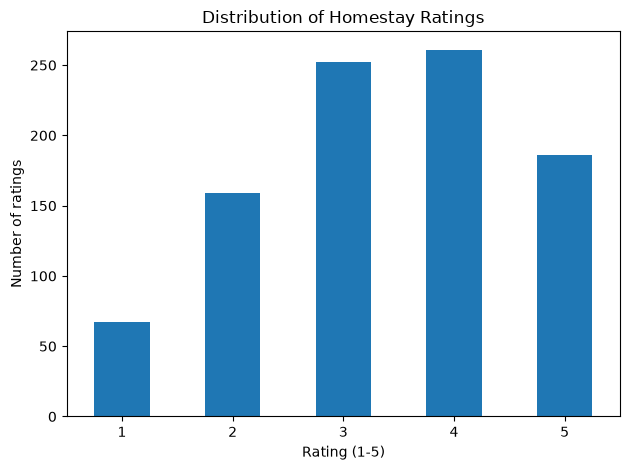

In [ ]:
ratings["rating"].value_counts().sort_index().plot(
    kind = "bar"
)
plt.title("Distribution of Homestay Ratings")
plt.xlabel("Rating (1-5)")
plt.ylabel("Number of ratings")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

### Ratings Per Homestay(Items)

Number of homestays: 38
Minimum ratings: 4
Maximum ratings: 59


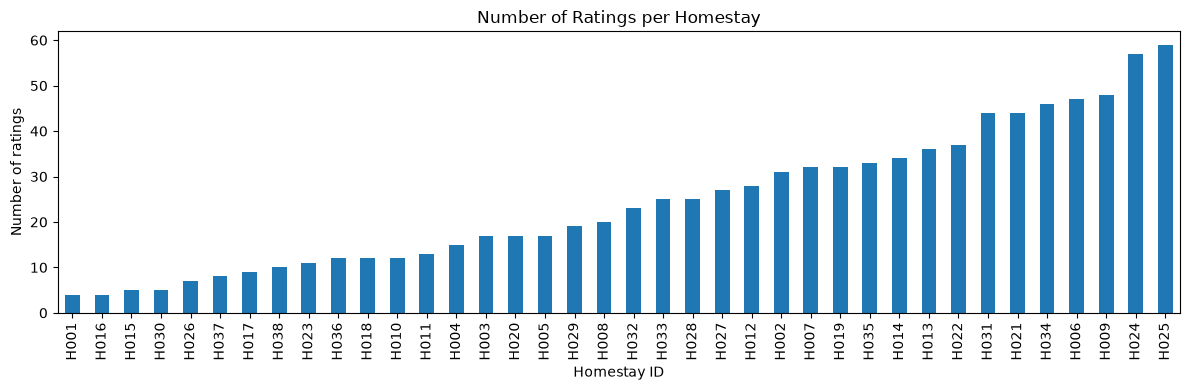

In [ ]:
ratings_per_item = ratings.groupby("item_id").size()

print("Number of homestays:", len(ratings_per_item))
print("Minimum ratings:", ratings_per_item.min())
print("Maximum ratings:", ratings_per_item.max())
ratings_per_item.sort_values().plot(kind="bar", figsize=(12, 4))
plt.title("Number of Ratings per Homestay")
plt.xlabel("Homestay ID")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()

#### 
Understanding the Dataset

The users represent visitors interested in staying at homestays in West and North Sikkim, while the items represent the 38 available homestays. Each rating is a score from 1 to 5 given by a visitor after a stay, indicating their satisfaction with that homestay. The user-item rating matrix has 120 rows and 38 columns, with 925 observed ratings out of 4,560 possible ratings. Its sparsity is approximately 79.7%, meaning most visitors have not rated most homestays, so a recommender system can help identify suitable places for future visits.

## Task 2 (Content-based Recommender)

### Importing and Splitting Data (80% for Training, 20% Testing)

In [6]:
from sklearn.model_selection import train_test_split

train_ratings, test_ratings = train_test_split(
    ratings,
    test_size = 0.20,
    random_state = 42
)

train_ratings = train_ratings.reset_index(drop = True)
test_ratings = test_ratings.reset_index(drop = True)

print("Training ratings:", len(train_ratings))
print("Testing ratings:", len(test_ratings))
print("Total ratings:", len(train_ratings) + len(test_ratings))

Training ratings: 740
Testing ratings: 185
Total ratings: 925


### Selecting and Scaling the Homestay Features

In [7]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity

features_cols = [
    "distance_from_gangtok_km",
    "price_per_night_inr",
    "rooms",
    "mountain_view",
    "near_monastery",
    "organic_food",
    "trek_access",
    "family_friendly"
]

X = items[features_cols].astype(float)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("Features matrix shape:", X_scaled.shape)
print("Scaled features matrix:", X_scaled.min(), "to", X_scaled.max())

Features matrix shape: (38, 8)
Scaled features matrix: 0.0 to 1.0


### Visitor's Preference Profile

In [8]:
features_df = pd.DataFrame(
    X_scaled,
    index = items["item_id"],
    columns = features_cols
)
#print(f"Features DataFrame shape: {features_df}") // For Viewing the features DataFrame, uncomment the line above.
liked_ratings = train_ratings[train_ratings["rating"] >= 4]

users_with_likes = sorted(liked_ratings["user_id"].unique())

print("Visitors with at least one 4- or 5-star rating:", len(users_with_likes))

selected_users = users_with_likes[:5]

print("Selected visitors:", selected_users)

Visitors with at least one 4- or 5-star rating: 98
Selected visitors: ['U001', 'U003', 'U004', 'U005', 'U006']


### Top 5 recommendations

In [9]:
content_recommendations = {}

for user_id in selected_users:
    liked_ids = liked_ratings.loc[
        liked_ratings["user_id"] == user_id, "item_id"
    ].tolist()

    user_profile = features_df.loc[liked_ids].mean(axis = 0)

    seen_ids = set(
        train_ratings.loc[
            train_ratings["user_id"] == user_id, "item_id"
        ]
    )

    candidate_ids = [
        item_id for item_id in features_df.index
        if item_id not in seen_ids
    ]

    scores = cosine_similarity(
        user_profile.to_numpy().reshape(1, -1),
        features_df.loc[candidate_ids].to_numpy()
    )[0]

    ranked = pd.DataFrame({
        "item_id": candidate_ids,
        "similarity": scores
    }).sort_values("similarity", ascending = False)

    ranked = ranked.merge(
        items[["item_id", "name","village","district"]],
        on = "item_id",
        how = "left"
    )

    top5 = ranked.head(5).reset_index(drop = True)
    
    content_recommendations[user_id] = top5

    print(f"\n Visitor: {user_id}")
    print("Previously liked homestays:",
        items.loc[
            items["item_id"].isin(liked_ids),"name"
        ].tolist())

    display(
        top5[
            ["item_id","name", "village", "district", "similarity"]
            ].round({"similarity": 3})
            )



 Visitor: U001
Previously liked homestays: ['Temi Heritage House', 'Aritar Heritage House', 'Yuksom Homestay', 'Rinchenpong Cottage', 'Martam Farm Stay', 'Dentam Farm Stay']


,item_id,name,village,district,similarity
0,H029,Uttarey Homestay,Uttarey,Gyalshing,0.914
1,H016,Kaluk Farm Stay,Kaluk,Soreng,0.904
2,H024,Hee Bermiok Eco Lodge,Hee Bermiok,Gyalshing,0.880
3,H007,Yuksom Heritage House,Yuksom,Gyalshing,0.877
4,H038,Tingvong Homestay,Tingvong,Mangan,0.873



 Visitor: U003
Previously liked homestays: ['Lachung Heritage House', 'Dentam Cottage', 'Borong Heritage House', 'Sang Eco Lodge', 'Yuksom Homestay', 'Rinchenpong Cottage']


,item_id,name,village,district,similarity
0,H035,Dzongu Eco Lodge,Dzongu,Mangan,0.907
1,H029,Uttarey Homestay,Uttarey,Gyalshing,0.906
2,H009,Okhrey Homestay,Okhrey,Soreng,0.839
3,H027,Pelling Eco Lodge,Pelling,Gyalshing,0.837
4,H003,Pelling Heritage House,Pelling,Gyalshing,0.830



 Visitor: U004
Previously liked homestays: ['Pastanga Farm Stay', 'Tingvong Homestay']


,item_id,name,village,district,similarity
0,H016,Kaluk Farm Stay,Kaluk,Soreng,0.964
1,H017,Temi Heritage House,Temi,Namchi,0.963
2,H004,Rumtek Eco Lodge,Rumtek,Gangtok,0.848
3,H030,Pastanga Eco Lodge,Pastanga,Pakyong,0.820
4,H014,Tingvong Farm Stay,Tingvong,Mangan,0.810



 Visitor: U005
Previously liked homestays: ['Pastanga Farm Stay', 'Lachen Homestay']


,item_id,name,village,district,similarity
0,H038,Tingvong Homestay,Tingvong,Mangan,0.921
1,H009,Okhrey Homestay,Okhrey,Soreng,0.912
2,H016,Kaluk Farm Stay,Kaluk,Soreng,0.908
3,H021,Zuluk Eco Lodge,Zuluk,Pakyong,0.907
4,H017,Temi Heritage House,Temi,Namchi,0.881



 Visitor: U006
Previously liked homestays: ['Yuksom Heritage House', 'Okhrey Homestay', 'Martam Homestay', 'Dentam Cottage', 'Uttarey Homestay', 'Lachung Cottage', 'Okhrey Farm Stay']


,item_id,name,village,district,similarity
0,H003,Pelling Heritage House,Pelling,Gyalshing,0.903
1,H008,Lachung Heritage House,Lachung,Mangan,0.900
2,H031,Yuksom Homestay,Yuksom,Gyalshing,0.899
3,H034,Rinchenpong Cottage,Rinchenpong,Soreng,0.872
4,H023,Lachen Homestay,Lachen,Mangan,0.857


### Prove of Recommendation Based on the previous Ratings on the basis of Features

In [10]:

# Examine the first selected visitor
user_id = selected_users[0]

liked_ids = liked_ratings.loc[
    liked_ratings["user_id"] == user_id,
    "item_id"
].tolist()

recommended_ids = content_recommendations[user_id][
    "item_id"
].tolist()

print("Visitor:", user_id)

print("\nFeatures of liked homestays:")
display(
    items.loc[
        items["item_id"].isin(liked_ids),
        ["name"] + features_cols
    ]
)

print("\nFeatures of recommended homestays:")
display(
    items.loc[
        items["item_id"].isin(recommended_ids),
        ["name"] + features_cols
    ]
)


Visitor: U001

Features of liked homestays:


,name,distance_from_gangtok_km,price_per_night_inr,rooms,mountain_view,near_monastery,organic_food,trek_access,family_friendly
16,Temi Heritage House,75,3400,5,1,0,1,0,1
18,Aritar Heritage House,70,3500,6,1,0,0,0,1
30,Yuksom Homestay,130,1800,6,1,1,1,1,1
33,Rinchenpong Cottage,120,2200,3,1,1,1,1,0
35,Martam Farm Stay,145,2600,6,1,0,0,0,0
36,Dentam Farm Stay,135,2700,7,0,0,1,1,0



Features of recommended homestays:


,name,distance_from_gangtok_km,price_per_night_inr,rooms,mountain_view,near_monastery,organic_food,trek_access,family_friendly
6,Yuksom Heritage House,130,4100,8,1,0,0,1,1
15,Kaluk Farm Stay,118,2300,8,1,0,1,0,1
23,Hee Bermiok Eco Lodge,125,3800,7,1,0,1,0,0
28,Uttarey Homestay,150,2500,8,1,0,1,1,0
37,Tingvong Homestay,80,2100,5,1,0,1,0,1


### Explanation of Recommendations

For visitor U001, the content-based recommender identified six previously liked homestays based on ratings of 4 or 5. The system created a user preference profile by calculating the average of their scaled item features and compared it with the features of unrated homestays using cosine similarity. Uttarey Homestay received the highest similarity score of 0.914, followed by Kaluk Farm Stay with 0.904 and Hee Bermiok Eco Lodge with 0.880. These recommendations indicate that the selected homestays have feature combinations that closely match the visitor's previously preferred homestays. Therefore, the system can suggest new accommodation options based on the visitor's existing preferences.

## Task 3 (Item-based collaborative filtering)

### Creating Rating Matrix from the Training Data

In [17]:
#rating matrix user-item using the Training ratings data
rating_matrix = train_ratings.pivot(
    index = "user_id",
    columns = "item_id",
    values = "rating"
)
#Calculate each user's average rating
user_means = rating_matrix.mean(axis = 1)

print("Rating matrix shape:", rating_matrix.shape)
print("\nUser average ratings:")
print(user_means.head())

Rating matrix shape: (120, 38)

User average ratings:
user_id
U001    4.285714
U002    1.875000
U003    4.000000
U004    3.400000
U005    2.500000
dtype: float64


### Centered matrix

In [18]:
#Subract each user's average rating from their ratings to create a mean-centered matrix
centered_matrix = rating_matrix.sub(user_means, axis = 0)

print(centered_matrix.head())

item_id  H001  H002   H003  H004  H005   H006  H007  H008  H009  H010  ...  \
user_id                                                                ...   
U001      NaN   NaN    NaN   NaN   NaN    NaN   NaN   NaN   NaN   NaN  ...   
U002      NaN   NaN -0.875   NaN   NaN  1.125   NaN   NaN   NaN   NaN  ...   
U003      NaN  -1.0    NaN   NaN   NaN -1.000   NaN   1.0   NaN   NaN  ...   
U004      NaN   NaN    NaN   NaN   NaN  0.600   NaN   NaN   NaN   NaN  ...   
U005      NaN   NaN -0.500   NaN   NaN  1.500   NaN   NaN   NaN   NaN  ...   

item_id  H029  H030      H031  H032   H033      H034  H035      H036  \
user_id                                                                
U001      NaN   NaN  0.714286   NaN    NaN  0.714286   NaN -0.285714   
U002      NaN   NaN       NaN   NaN  0.125  0.125000   NaN       NaN   
U003      NaN   NaN  0.000000   NaN    NaN  1.000000   NaN       NaN   
U004      NaN   NaN       NaN   NaN    NaN       NaN   NaN       NaN   
U005     -0.5   NaN  

### Creating Items similarity Matrix

In [19]:
#Convert the mean-centered matrix to a NumPy array for similarity calculations
centered_array = centered_matrix.to_numpy()

n_items = centered_array.shape[1]

#Create an empty similarity matrix
items_similarity = np.zeros((n_items, n_items))

#Calculate the cosine similarity between each pair of items
for i in range(n_items):
    for j in range(n_items):
        #User who rated both items
        common_users = (
            ~np.isnan(centered_array[:, i]) &
            ~np.isnan(centered_array[:, j])
        )
        #Get the ratings of the common users for both items
        vector_a = centered_array[common_users, i]
        vector_b = centered_array[common_users, j]

        #Calculate the cosine similarity
        if len(vector_a)>0:
            numerator = np.dot(vector_a, vector_b)

            denominator = (
                np.linalg.norm(vector_a) *
                np.linalg.norm(vector_b)
            )
            if denominator !=0:
                items_similarity[i, j] = numerator / denominator
print("Item similarity matrix shape:", items_similarity.shape)

Item similarity matrix shape: (38, 38)


### Creating Function for Predicting the Ratings 

In [20]:
#Store the homestay IDs in the same order as the similarity matrix
items_ids = rating_matrix.columns.tolist()

#Function for Predicting the rating for a given user and target item using item-based collaborative filtering
def predict_rating(user_id, target_item_id):
    user_mean = user_means.loc[user_id] # User's average rating
    user_ratings = rating_matrix.loc[user_id].dropna() #User's ratings for items they have rated
    target_index = items_ids.index(target_item_id) #Get the index of the target item in the similarity matrix

    similar_items = []  #Store similarities and rating deviations

    for rated_item_id,actual_rating in user_ratings.items():
        #Find the position of already rated homestay
        rated_index = items_ids.index(rated_item_id)

        #Get the similarity between the target item and the rated item
        similarity = items_similarity[target_index, rated_index]

        #Use positively similar Homestay
        if similarity > 0:
            deviation = actual_rating - user_mean
            similar_items.append((similarity, deviation))

    #Select the 10 most similar rated Homestays

    similar_items.sort(key=lambda x: x[0], reverse=True)
    similar_items = similar_items[:10]

    #If no useful similar items exits, use the User's average rating
    if len(similar_items) == 0:
        return user_mean

    #calculate the weighted average of the rating deviations
    numerator = sum(sim * deviation for sim, deviation in similar_items)
    denominator = sum(abs(sim) for sim, deviation in similar_items)

    if denominator == 0:
        return user_mean

    predicted_rating = user_mean + (numerator / denominator)

    #Keep prediction within the valid rating range (1-5)
    prediction = np.clip(predicted_rating, 1, 5)

    return prediction



### Top 5 Recommendation from Prediction

In [21]:
item_recommendations = {}

for user_id in selected_users:

    # Find homestays already rated by the user
    seen_items = set(
        rating_matrix.loc[user_id].dropna().index
    )

    # Find homestays not yet rated by the user
    candidate_items = [
        item_id for item_id in items_ids
        if item_id not in seen_items
    ]

    # Predict ratings for all candidate homestays
    predictions = []

    for item_id in candidate_items:
        predicted = predict_rating(user_id, item_id)

        predictions.append({
            "item_id": item_id,
            "predicted_rating": predicted
        })

    # Sort by predicted rating
    recommendations = pd.DataFrame(predictions)

    recommendations = recommendations.sort_values(
        by="predicted_rating",
        ascending=False
    )

    # Add homestay details
    recommendations = recommendations.merge(
        items[["item_id", "name", "village", "district"]],
        on="item_id",
        how="left"
    )

    # Keep the top 5
    top5 = recommendations.head(5).reset_index(drop=True)

    item_recommendations[user_id] = top5

    print(f"\nTop 5 recommendations for {user_id}:")
    print(top5.to_string(index=False))


Top 5 recommendations for U001:
item_id  predicted_rating               name  village  district
   H004               5.0   Rumtek Eco Lodge   Rumtek   Gangtok
   H006               5.0 Pastanga Farm Stay Pastanga   Pakyong
   H011               5.0   Dzongu Farm Stay   Dzongu    Mangan
   H013               5.0     Dentam Cottage   Dentam Gyalshing
   H038               5.0  Tingvong Homestay Tingvong    Mangan

Top 5 recommendations for U003:
item_id  predicted_rating                  name     village  district
   H011          4.955050      Dzongu Farm Stay      Dzongu    Mangan
   H033          4.901926      Okhrey Farm Stay      Okhrey    Soreng
   H027          4.755330     Pelling Eco Lodge     Pelling Gyalshing
   H010          4.695990 Rinchenpong Farm Stay Rinchenpong    Soreng
   H020          4.555434    Ravangla Farm Stay    Ravangla    Namchi

Top 5 recommendations for U004:
item_id  predicted_rating                  name     village  district
   H009               4.0  

### Verify the Prediction

In [22]:
for user_id in selected_users:

    print(f"\nUser: {user_id}")

    for item_id in item_recommendations[user_id]["item_id"]:

        user_ratings = rating_matrix.loc[user_id].dropna()
        target_index = items_ids.index(item_id)

        similarities = []

        for rated_item_id in user_ratings.index:
            rated_index = items_ids.index(rated_item_id)

            similarity = items_similarity[target_index, rated_index]

            if similarity > 0:
                similarities.append(similarity)

        print(
            item_id,
            "| Positive similar items:", len(similarities),
            "| Top similarity:", round(max(similarities), 3)
            if similarities else "None"
        )


User: U001
H004 | Positive similar items: 1 | Top similarity: 0.687
H006 | Positive similar items: 1 | Top similarity: 0.18
H011 | Positive similar items: 1 | Top similarity: 1.0
H013 | Positive similar items: 1 | Top similarity: 0.555
H038 | Positive similar items: 2 | Top similarity: 1.0

User: U003
H011 | Positive similar items: 3 | Top similarity: 1.0
H033 | Positive similar items: 5 | Top similarity: 0.807
H027 | Positive similar items: 4 | Top similarity: 1.0
H010 | Positive similar items: 3 | Top similarity: 1.0
H020 | Positive similar items: 5 | Top similarity: 1.0

User: U004
H009 | Positive similar items: 1 | Top similarity: 0.147
H023 | Positive similar items: 1 | Top similarity: 0.829
H012 | Positive similar items: 1 | Top similarity: 0.282
H014 | Positive similar items: 2 | Top similarity: 1.0
H024 | Positive similar items: 1 | Top similarity: 1.0

User: U005
H017 | Positive similar items: 1 | Top similarity: 0.18
H011 | Positive similar items: 1 | Top similarity: 1.0
H02

### Summary

An item-based collaborative filtering recommendation system was implemented using NumPy. First, a user-item rating matrix was created using the training dataset. The ratings were mean-centred to account for differences in individual user rating behaviour. Cosine similarity was then calculated between homestays using the ratings of common users. For each user, the system predicted ratings for previously unrated homestays using up to 10 similar homestays and generated the top five recommendations. The system produced recommendations for U001, U003 and U004, with predicted ratings ranging from 4.0 to 5.0.

## Task 4 (Evaluate and compare)

In [23]:
print("Training ratings:", len(train_ratings))
print("Testing ratings:", len(test_ratings))

Training ratings: 740
Testing ratings: 185


### Model 1: Item-average baseline

In [ ]:
# Calculate the overall average rating
item_average = train_ratings.groupby("item_id")["rating"].mean()

# Predict ratings for the test dataset
global_average = train_ratings["rating"].mean()

baseline_predictions = []

for _, row in test_ratings.iterrows():
    item_id = row["item_id"]

    # Use item average; if not available, use global average
    predicted_rating = item_average.get(item_id, global_average)

    baseline_predictions.append(predicted_rating)

print("First 5 baseline predictions:")
print(baseline_predictions[:5])

First 5 baseline predictions:
[np.float64(4.3428571428571425), np.float64(2.5), np.float64(3.861111111111111), np.float64(3.4347826086956523), np.float64(3.923076923076923)]


### Model 2: Item-based collaborative filtering

In [ ]:
cf_predictions = []

for _, row in test_ratings.iterrows():
    user_id = row["user_id"]
    item_id = row["item_id"]

    # Handles users or items missing from training data
    if user_id in user_means.index and item_id in items_ids:
        predicted_rating = predict_rating(user_id, item_id)
    else:
        predicted_rating = global_average

    cf_predictions.append(predicted_rating)

print("First 5 collaborative filtering predictions:")
print(cf_predictions[:5])


First 5 collaborative filtering predictions:
[np.float64(3.695774027856602), np.float64(2.0), np.float64(3.4), np.float64(3.0), np.float64(1.7371459061184473)]


### Model 3: Content-based rating prediction

In [26]:
# Calculate similarity between all homestay feature vectors
content_similarity = cosine_similarity(
    X_scaled,
    X_scaled
)

# Create an item ID to matrix position mapping
content_item_ids = items["item_id"].tolist()

content_item_index = {
    item_id: index
    for index, item_id in enumerate(content_item_ids)
}


def predict_content_rating(user_id, target_item_id):

    # Get only this user's training ratings
    user_history = train_ratings[
        train_ratings["user_id"] == user_id
    ]

    if user_history.empty:
        return global_average

    # Find target homestay position
    target_index = content_item_index[target_item_id]

    similarities = []

    for _, history_row in user_history.iterrows():

        rated_item_id = history_row["item_id"]
        actual_rating = history_row["rating"]

        rated_index = content_item_index[rated_item_id]

        similarity = content_similarity[
            target_index, rated_index
        ]

        if similarity > 0:
            similarities.append((similarity, actual_rating))

    # Select the 10 most similar rated homestays
    similarities.sort(key=lambda x: x[0], reverse=True)
    similarities = similarities[:10]

    if not similarities:
        return global_average

    # Calculate similarity-weighted predicted rating
    numerator = sum(
        similarity * rating
        for similarity, rating in similarities
    )

    denominator = sum(
        similarity
        for similarity, rating in similarities
    )

    prediction = numerator / denominator

    return np.clip(prediction, 1, 5)


# Predict ratings for all test rows
content_predictions = []

for _, row in test_ratings.iterrows():

    predicted_rating = predict_content_rating(
        row["user_id"],
        row["item_id"]
    )

    content_predictions.append(predicted_rating)


print("First 5 content-based predictions:")
print(content_predictions[:5])

First 5 content-based predictions:
[np.float64(3.532341010497461), np.float64(2.045492070763033), np.float64(3.4264474447414965), np.float64(3.3615705819626176), np.float64(1.2898229777235015)]


### Calculate RMSE for all three models

In [27]:
# Actual ratings from the test dataset
actual_ratings = test_ratings["rating"].to_numpy()

# Calculate RMSE for each model
baseline_rmse = np.sqrt(
    np.mean((actual_ratings - np.array(baseline_predictions)) ** 2)
)

cf_rmse = np.sqrt(
    np.mean((actual_ratings - np.array(cf_predictions)) ** 2)
)

content_rmse = np.sqrt(
    np.mean((actual_ratings - np.array(content_predictions)) ** 2)
)

# Create comparison table
rmse_results = pd.DataFrame({
    "Recommendation Model": [
        "Item-average baseline",
        "Item-based collaborative filtering",
        "Content-based filtering"
    ],
    "RMSE": [
        baseline_rmse,
        cf_rmse,
        content_rmse
    ]
})

rmse_results = rmse_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print(rmse_results.to_string(index=False))

              Recommendation Model     RMSE
           Content-based filtering 0.898732
Item-based collaborative filtering 0.999392
             Item-average baseline 1.184991


In [28]:
best_model = rmse_results.iloc[0]

print("Best performing model:", best_model["Recommendation Model"])
print("Lowest RMSE:", round(best_model["RMSE"], 4))

Best performing model: Content-based filtering
Lowest RMSE: 0.8987


### Check that all predictions are valid

In [31]:
print("Test ratings:", len(actual_ratings))
print("Baseline predictions:", len(baseline_predictions))
print("Collaborative predictions:", len(cf_predictions))
print("Content-based predictions:", len(content_predictions))

print("\nPrediction ranges:")
print("Baseline:", min(baseline_predictions), "to", max(baseline_predictions))
print("Collaborative:", min(cf_predictions), "to", max(cf_predictions))
print("Content-based:", min(content_predictions), "to", max(content_predictions))


Test ratings: 185
Baseline predictions: 185
Collaborative predictions: 185
Content-based predictions: 185

Prediction ranges:
Baseline: 1.5 to 4.5
Collaborative: 1.0 to 5.0
Content-based: 1.2650486929258344 to 4.7976056294391105


The three recommendation models were evaluated using RMSE on 185 test ratings. Content-based filtering achieved the lowest RMSE of 0.898732, followed by item-based collaborative filtering with 0.999392. The item-average baseline recorded the highest RMSE of 1.184991. These results indicate that content-based filtering provided the most accurate rating predictions on the given dataset. Therefore, it is the preferred recommendation approach based on this evaluation.

## Bonus -- Matrix Factorisation

### Prepare the data

In [32]:
# Create mappings for users and homestays
mf_users = sorted(train_ratings["user_id"].unique())
mf_items = sorted(train_ratings["item_id"].unique())

user_to_index = {
    user: index for index, user in enumerate(mf_users)
}

item_to_index = {
    item: index for index, item in enumerate(mf_items)
}

# Convert training ratings into numerical indices
mf_train = [
    (
        user_to_index[row.user_id],
        item_to_index[row.item_id],
        row.rating
    )
    for row in train_ratings.itertuples()
]

# Convert test ratings into numerical indices
mf_test = [
    (
        user_to_index.get(row.user_id, -1),
        item_to_index.get(row.item_id, -1),
        row.rating
    )
    for row in test_ratings.itertuples()
]

# Calculate the global average training rating
mf_global_mean = train_ratings["rating"].mean()

print("Number of users:", len(mf_users))
print("Number of homestays:", len(mf_items))
print("Training records:", len(mf_train))
print("Testing records:", len(mf_test))
print("Global average rating:", round(mf_global_mean, 3))

Number of users: 120
Number of homestays: 38
Training records: 740
Testing records: 185
Global average rating: 3.351


### Implement matrix factorisation using gradient descent

In [33]:
def train_matrix_factorization(
    train_data,
    n_users,
    n_items,
    global_mean,
    latent_factors=10,
    learning_rate=0.01,
    regularization=0.01,
    epochs=100,
    seed=42
):

    rng = np.random.default_rng(seed)

    # Initialise user and item factor matrices
    P = rng.normal(0, 0.1, (n_users, latent_factors))
    Q = rng.normal(0, 0.1, (n_items, latent_factors))

    cost_history = []

    for epoch in range(epochs):

        # Shuffle training records
        shuffled_data = rng.permutation(len(train_data))

        for index in shuffled_data:

            user_index, item_index, actual_rating = train_data[index]

            # Calculate predicted rating
            prediction = (
                global_mean +
                np.dot(P[user_index], Q[item_index])
            )

            # Calculate prediction error
            error = actual_rating - prediction

            # Save old user factors before updating
            old_user_factors = P[user_index].copy()

            # Update user factors
            P[user_index] += learning_rate * (
                error * Q[item_index] -
                regularization * P[user_index]
            )

            # Update item factors
            Q[item_index] += learning_rate * (
                error * old_user_factors -
                regularization * Q[item_index]
            )

        # Calculate total regularised cost after each epoch
        total_error = 0

        for user_index, item_index, actual_rating in train_data:

            prediction = (
                global_mean +
                np.dot(P[user_index], Q[item_index])
            )

            total_error += (actual_rating - prediction) ** 2

        regularization_cost = regularization / 2 * (
            np.sum(P ** 2) + np.sum(Q ** 2)
        )

        cost = (total_error / 2) + regularization_cost

        cost_history.append(cost)

    return P, Q, cost_history

### Train using two different lambda values

In [34]:
# Train model with lambda = 0.01
P_001, Q_001, cost_001 = train_matrix_factorization(
    mf_train,
    len(mf_users),
    len(mf_items),
    mf_global_mean,
    regularization=0.01
)

# Train model with lambda = 0.1
P_01, Q_01, cost_01 = train_matrix_factorization(
    mf_train,
    len(mf_users),
    len(mf_items),
    mf_global_mean,
    regularization=0.1
)

print("Both matrix factorisation models trained successfully.")

Both matrix factorisation models trained successfully.


### Plot cost versus iterations

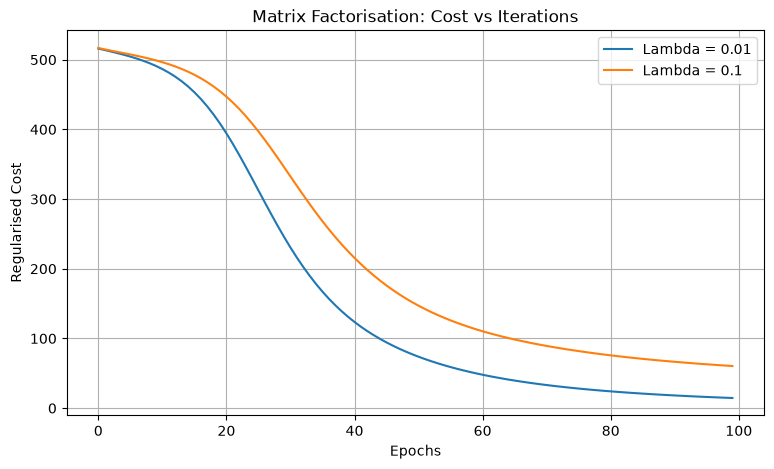

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(cost_001, label="Lambda = 0.01")
plt.plot(cost_01, label="Lambda = 0.1")

plt.xlabel("Epochs")
plt.ylabel("Regularised Cost")
plt.title("Matrix Factorisation: Cost vs Iterations")

plt.legend()
plt.grid(True)
plt.show()

### Evaluate both models using test RMSE

In [36]:
def evaluate_mf(P, Q, test_data, global_mean):

    predictions = []
    actual_values = []

    for user_index, item_index, actual_rating in test_data:

        # Use global average if user or item is unknown
        if user_index == -1 or item_index == -1:

            prediction = global_mean

        else:

            prediction = (
                global_mean +
                np.dot(P[user_index], Q[item_index])
            )

        # Keep prediction within 1-5
        prediction = np.clip(prediction, 1, 5)

        predictions.append(prediction)
        actual_values.append(actual_rating)

    rmse = np.sqrt(
        np.mean(
            (np.array(actual_values) - np.array(predictions)) ** 2
        )
    )

    return rmse


# Evaluate both lambda values
rmse_001 = evaluate_mf(P_001, Q_001, mf_test, mf_global_mean)
rmse_01 = evaluate_mf(P_01, Q_01, mf_test, mf_global_mean)

# Display comparison
mf_results = pd.DataFrame({
    "Lambda": [0.01, 0.1],
    "Test RMSE": [rmse_001, rmse_01]
})

print(mf_results.to_string(index=False))

 Lambda  Test RMSE
   0.01   1.092026
   0.10   1.012430


### Compare the bonus models with your previous models

In [37]:
all_results = pd.DataFrame({
    "Recommendation Model": [
        "Content-based filtering",
        "Item-based collaborative filtering",
        "Item-average baseline",
        "Matrix Factorisation (Lambda 0.01)",
        "Matrix Factorisation (Lambda 0.1)"
    ],
    "RMSE": [
        content_rmse,
        cf_rmse,
        baseline_rmse,
        rmse_001,
        rmse_01
    ]
})

all_results = all_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print(all_results.to_string(index=False))

              Recommendation Model     RMSE
           Content-based filtering 0.898732
Item-based collaborative filtering 0.999392
 Matrix Factorisation (Lambda 0.1) 1.012430
Matrix Factorisation (Lambda 0.01) 1.092026
             Item-average baseline 1.184991


Matrix Factorisation was implemented using Stochastic Gradient Descent (SGD) with 10 latent factors. Two regularisation values, λ = 0.01 and λ = 0.1, were tested over 100 epochs. The cost-versus-iterations graph showed that the cost decreased during training for both models. On the test dataset, λ = 0.1 achieved an RMSE of 1.012430, while λ = 0.01 achieved 1.092026. Therefore, λ = 0.1 performed better on unseen ratings, indicating that stronger regularisation improved generalisation in this experiment.